In [1]:
import pandas as pd

In [2]:
url = "https://drive.google.com/file/d/1Ox_W3R9HksjIh_gvWgmmx5c-FqbD9vVj/view?usp=sharing"
path = 'https://drive.google.com/uc?export=download&id='+url.split('/')[-2]
df = pd.read_csv(path)
df.head()


,Unnamed: 0,step,type,branch,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,unusuallogin,isFlaggedFraud,Acct type,Date of transaction,Time of day,isFraud
0,0,1,PAYMENT,Indonesia,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,9,0,Current,3/1/2018,Morning,0.0
1,1,1,PAYMENT,India,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,10,0,Savings,5/1/2018,Morning,0.0
2,2,1,TRANSFER,India,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,2,0,Current,7/1/2018,Morning,1.0
3,3,1,CASH_OUT,Australia,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,Current,6/1/2018,Afternoon,1.0
4,4,1,PAYMENT,Australia,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,17,0,Current,6/1/2018,Morning,0.0


In [3]:
df.head()
df.info()
df['isFraud'].value_counts(normalize=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0           10127 non-null  int64  
 1   step                 10127 non-null  int64  
 2   type                 10123 non-null  object 
 3   branch               10127 non-null  object 
 4   amount               10125 non-null  float64
 5   nameOrig             10121 non-null  object 
 6   oldbalanceOrg        10125 non-null  float64
 7   newbalanceOrig       10127 non-null  float64
 8   nameDest             10121 non-null  object 
 9   oldbalanceDest       10126 non-null  float64
 10  newbalanceDest       10125 non-null  float64
 11  unusuallogin         10127 non-null  int64  
 12  isFlaggedFraud       10127 non-null  int64  
 13  Acct type            10117 non-null  object 
 14  Date of transaction  10120 non-null  object 
 15  Time of day          10125 non-null 

,proportion
isFraud,
0.0,0.993284
1.0,0.006716


In [4]:
df.describe()

,Unnamed: 0,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,unusuallogin,isFlaggedFraud,isFraud
count,10127.000000,10127.000000,1.012500e+04,1.012500e+04,1.012700e+04,1.012600e+04,1.012500e+04,10127.000000,10127.0,10125.000000
mean,5063.000000,4.214279,1.048869e+05,8.836965e+05,9.044703e+05,9.335393e+05,1.109315e+06,10.513183,0.0,0.006716
std,2923.557422,2.484139,2.706369e+05,2.124554e+06,2.169946e+06,2.677976e+06,3.048644e+06,5.809233,0.0,0.081680
min,0.000000,1.000000,2.390000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.0,0.000000
25%,2531.500000,1.000000,4.397380e+03,1.290000e+02,0.000000e+00,0.000000e+00,0.000000e+00,6.000000,0.0,0.000000
50%,5063.000000,5.000000,1.279831e+04,2.136300e+04,1.021224e+04,0.000000e+00,0.000000e+00,10.000000,0.0,0.000000
75%,7594.500000,7.000000,1.143818e+05,1.724320e+05,1.707240e+05,2.819345e+05,2.523925e+05,16.000000,0.0,0.000000
max,10126.000000,7.000000,1.000000e+07,1.290000e+07,1.300000e+07,1.950000e+07,2.260000e+07,20.000000,0.0,1.000000


In [5]:
df['isFraud'].value_counts()

,count
isFraud,
0.0,10057
1.0,68


In [ ]:
df['isFraud'].value_counts(normalize=True) * 100

,proportion
isFraud,
0.0,99.328395
1.0,0.671605


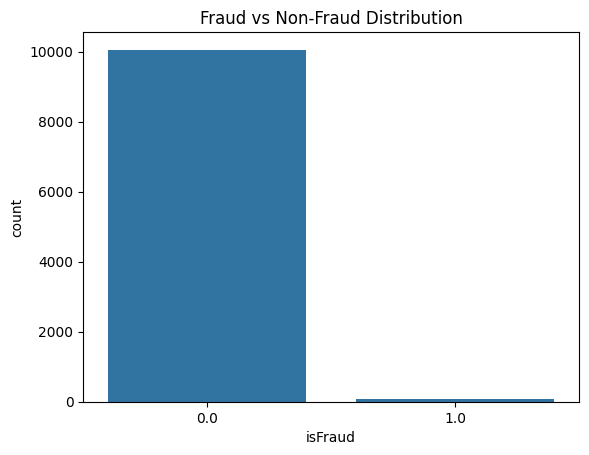

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x='isFraud')
plt.title("Fraud vs Non-Fraud Distribution")
plt.show()

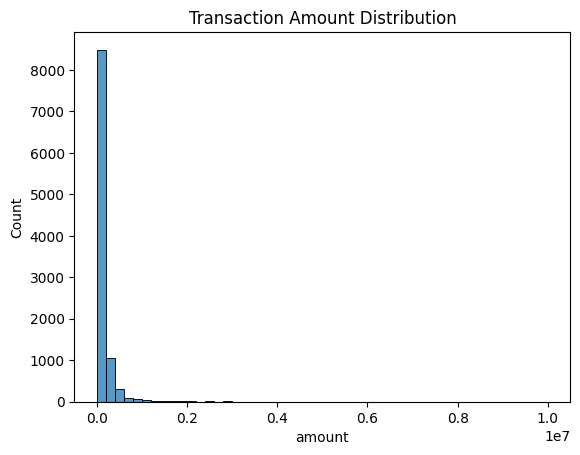

In [7]:
sns.histplot(df['amount'], bins=50)
plt.title("Transaction Amount Distribution")
plt.show()

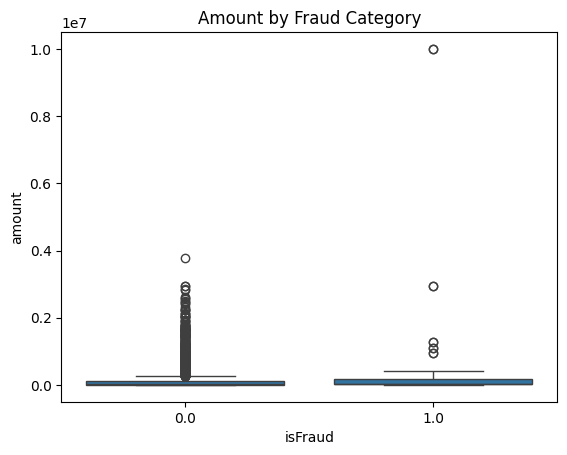

In [8]:
sns.boxplot(data=df, x='isFraud', y='amount')
plt.title("Amount by Fraud Category")
plt.show()

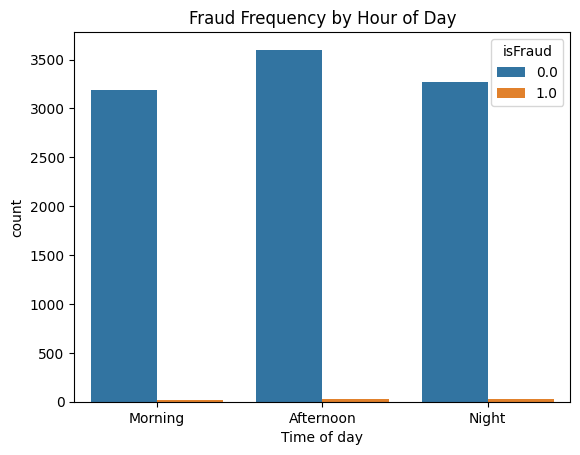

In [9]:
sns.countplot(data=df, x='Time of day', hue='isFraud')
plt.title("Fraud Frequency by Hour of Day")
plt.show()


<Axes: xlabel='type', ylabel='count'>

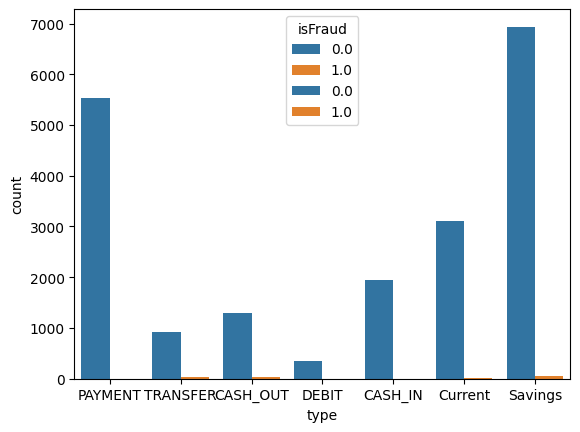

In [10]:
sns.countplot(x='type', hue='isFraud', data=df)
sns.countplot(x='Acct type', hue='isFraud', data=df)


Feature engineering is the process of:

 Creating new, meaningful variables (features)
 From the raw data you already have

so that your machine learning model can understand patterns better.
With it, models become powerful, accurate, and explainable.

TOP ENGINEERED FEATURES FOR FRAUD MODEL:
Velocity Features (most powerful)

Fraudsters move very fast before accounts are blocked.


In [11]:
  #Number of Transactions per User
df['tx_count_user'] = df.groupby('nameOrig')['step'].transform('count')
df


,Unnamed: 0,step,type,branch,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,unusuallogin,isFlaggedFraud,Acct type,Date of transaction,Time of day,isFraud,tx_count_user
0,0,1,PAYMENT,Indonesia,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,9,0,Current,3/1/2018,Morning,0.0,1.0
1,1,1,PAYMENT,India,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,10,0,Savings,5/1/2018,Morning,0.0,1.0
2,2,1,TRANSFER,India,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,2,0,Current,7/1/2018,Morning,1.0,1.0
3,3,1,CASH_OUT,Australia,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,Current,6/1/2018,Afternoon,1.0,1.0
4,4,1,PAYMENT,Australia,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,17,0,Current,6/1/2018,Morning,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10122,10122,7,PAYMENT,Cuba,337.50,C1494306005,33107.0,32769.50,M1424027000,0.0,0.0,7,0,Current,3/1/2018,Afternoon,0.0,1.0
10123,10123,7,PAYMENT,Mexico,5003.57,C1633890169,32769.5,27765.93,M1854745805,0.0,0.0,11,0,Savings,5/1/2018,Morning,0.0,1.0
10124,10124,7,PAYMENT,Panama,10424.89,C1026138669,50780.0,40355.11,M1852900317,0.0,0.0,6,0,Savings,7/1/2018,Night,0.0,1.0
10125,10125,7,PAYMENT,Mexico,2823.59,C378659213,986.0,0.00,M301812950,0.0,0.0,12,0,Savings,6/1/2018,Night,0.0,1.0


In [12]:
 #Transactions Per Hour
df['tx_per_hour'] = df.groupby(['nameOrig', 'Time of day'])['amount'].transform('count')


In [13]:
 #Rolling 3-Step Transaction Count
df['tx_last_3'] = df.groupby('nameOrig')['step'].transform(lambda x: x.rolling(3).count())


In [14]:
#Average Time Between Transactions
df['time_diff'] = df.groupby('nameOrig')['step'].diff()

Amount-Based Features

These capture abnormal or unusual amounts.

In [15]:
df['avg_amount_user'] = df.groupby('nameOrig')['amount'].transform('mean')
df['amount_deviation'] = df['amount'] / (df['avg_amount_user'] + 1)

In [16]:
df['high_amount_flag'] = (df['amount'] > df['amount'].quantile(0.95)).astype(int)


In [17]:
df['balance_drop'] = df['oldbalanceOrg'] - df['newbalanceOrig']
df['delta_dest'] = df['oldbalanceDest'] + df['amount']


Behaviorial User Features

In [18]:
#High standard deviation = inconsistent behavior = red flag.
df['std_amount_user'] = df.groupby('nameOrig')['amount'].transform('std')


In [19]:
#Has the User Seen This Merchant Before?  Fraud often sends money to new destinations.
df['dest_tx_count'] = df.groupby(['nameOrig','nameDest'])['amount'].transform('count')
df['new_merchant_flag'] = (df['dest_tx_count'] == 1).astype(int)


Time Features

In [20]:
#Night-Time Flag

df['night_time_flag'] = df['Time of day'].isin([0,1,2,3,4]).astype(int)


In [21]:
#Certain days (like weekends) see more suspicious activity.
df['Date of transaction'] = pd.to_datetime(df['Date of transaction'], dayfirst=True)

# Step 2: extract day of the week
df['day_of_week'] = df['Date of transaction'].dt.dayofweek

Destination Account Risk

In [22]:
#If destination account receives a lot of money suddenly → suspicious.
df['dest_tx_count_total'] = df.groupby('nameDest')['amount'].transform('count')


In [23]:
#Accounts frequently receiving fraud transactions are high risk.
dest_fraud_rate = df.groupby('nameDest')['isFraud'].mean()
df['dest_fraud_risk'] = df['nameDest'].map(dest_fraud_rate)


Branch Fraud Rate

In [24]:
#Branches with high fraud histories are riskier.
branch_fraud_rate = df.groupby('branch')['isFraud'].mean()


Login & Device Risk
Combine Unusual Login + Amount

In [25]:
#If unusual login + large amount → VERY risky.
df['unusual_and_high_amount'] = df['unusuallogin'] * df['high_amount_flag']


Additional Flags

In [26]:
# Flag new destination (count == 1)
df['new_destination_flag'] = (df['dest_tx_count'] == 1).astype(int)

In [27]:
# Flag if balance drop is unusually large (e.g., >95th percentile)
df['large_balance_drop_flag'] = (df['balance_drop'] > df['balance_drop'].quantile(0.95)).astype(int)

In [28]:
# Flag unusually frequent users
df['frequent_transactions_flag'] = (df['tx_count_user'] > df['tx_count_user'].quantile(0.95)).astype(int)

In [29]:
# Flag branches with high fraud rate (e.g., >5%)
df['high_risk_branch_flag'] = (df['branch'].map(branch_fraud_rate) > 0.05).astype(int)

In [31]:
# Reset index to create a unique transaction ID
df.reset_index(inplace=True)
df.rename(columns={'index': 'transaction_id'}, inplace=True)

/tmp/ipython-input-162995854.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.rename(columns={'index': 'transaction_id'}, inplace=True)


In [32]:
df = df.dropna(subset=['isFraud'])

Droping not needed features

In [33]:
columns_to_drop = [
    'Unnamed: 0',
    'nameOrig',
    'nameDest',
    'Date of transaction',
    'transaction_id',
    'isFraud'  # target
]

X = df.drop(columns=columns_to_drop)
y = df['isFraud']
transaction_ids = df['transaction_id']

In [34]:
X

,step,type,branch,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,unusuallogin,isFlaggedFraud,...,new_merchant_flag,night_time_flag,day_of_week,dest_tx_count_total,dest_fraud_risk,unusual_and_high_amount,new_destination_flag,large_balance_drop_flag,frequent_transactions_flag,high_risk_branch_flag
0,1,PAYMENT,Indonesia,9839.64,170136.0,160296.36,0.0,0.0,9,0,...,1,0,2.0,1.0,0.000000,0,1,0,0,0
1,1,PAYMENT,India,1864.28,21249.0,19384.72,0.0,0.0,10,0,...,1,0,4.0,1.0,0.000000,0,1,0,0,0
2,1,TRANSFER,India,181.00,181.0,0.00,0.0,0.0,2,0,...,1,0,6.0,3.0,0.333333,0,1,0,0,0
3,1,CASH_OUT,Australia,181.00,181.0,0.00,21182.0,0.0,1,0,...,1,0,5.0,1.0,1.000000,0,1,0,0,0
4,1,PAYMENT,Australia,11668.14,41554.0,29885.86,0.0,0.0,17,0,...,1,0,5.0,1.0,0.000000,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10120,7,PAYMENT,Cuba,337.50,33107.0,32769.50,0.0,0.0,7,0,...,1,0,2.0,1.0,0.000000,0,1,0,0,0
10121,7,PAYMENT,Mexico,5003.57,32769.5,27765.93,0.0,0.0,11,0,...,1,0,4.0,1.0,0.000000,0,1,0,0,0
10122,7,PAYMENT,Panama,10424.89,50780.0,40355.11,0.0,0.0,6,0,...,1,0,6.0,1.0,0.000000,0,1,0,0,0
10123,7,PAYMENT,Mexico,2823.59,986.0,0.00,0.0,0.0,12,0,...,1,0,5.0,1.0,0.000000,0,1,0,0,0


In [35]:
X.columns

Index(['step', 'type', 'branch', 'amount', 'oldbalanceOrg', 'newbalanceOrig',
       'oldbalanceDest', 'newbalanceDest', 'unusuallogin', 'isFlaggedFraud',
       'Acct type', 'Time of day', 'tx_count_user', 'tx_per_hour', 'tx_last_3',
       'time_diff', 'avg_amount_user', 'amount_deviation', 'high_amount_flag',
       'balance_drop', 'delta_dest', 'std_amount_user', 'dest_tx_count',
       'new_merchant_flag', 'night_time_flag', 'day_of_week',
       'dest_tx_count_total', 'dest_fraud_risk', 'unusual_and_high_amount',
       'new_destination_flag', 'large_balance_drop_flag',
       'frequent_transactions_flag', 'high_risk_branch_flag'],
      dtype='object')

In [36]:
y

,isFraud
0,0.0
1,0.0
2,1.0
3,1.0
4,0.0
...,...
10120,0.0
10121,0.0
10122,0.0
10123,0.0


In [37]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score
import seaborn as sns
import matplotlib.pyplot as plt


Train/Test Split

In [38]:
X_train, X_test, y_train, y_test, train_ids, test_ids = train_test_split(
    X, y, transaction_ids, test_size=0.2, stratify=y, random_state=42
)


Identify column types

In [39]:
numeric_features = X.select_dtypes(include=['number']).columns.tolist()
categorical_features = X.select_dtypes(exclude=['number']).columns.tolist()
numeric_features

['step',
 'amount',
 'oldbalanceOrg',
 'newbalanceOrig',
 'oldbalanceDest',
 'newbalanceDest',
 'unusuallogin',
 'isFlaggedFraud',
 'tx_count_user',
 'tx_per_hour',
 'tx_last_3',
 'time_diff',
 'avg_amount_user',
 'amount_deviation',
 'high_amount_flag',
 'balance_drop',
 'delta_dest',
 'std_amount_user',
 'dest_tx_count',
 'new_merchant_flag',
 'night_time_flag',
 'day_of_week',
 'dest_tx_count_total',
 'dest_fraud_risk',
 'unusual_and_high_amount',
 'new_destination_flag',
 'large_balance_drop_flag',
 'frequent_transactions_flag',
 'high_risk_branch_flag']

In [40]:
categorical_features

['type', 'branch', 'Acct type', 'Time of day']

In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

In [42]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [43]:
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [44]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

Creating multiple models to compare

In [45]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

Define the Models (each wrapped in a pipeline)

In [46]:

pipeline_lr = Pipeline([
    ('preprocess', preprocessor),
    ('model', LogisticRegression(max_iter=2000))
])

pipeline_rf = Pipeline([
    ('preprocess', preprocessor),
    ('model', RandomForestClassifier())
])

pipeline_xgb = Pipeline([
    ('preprocess', preprocessor),
    ('model', XGBClassifier(
        eval_metric='logloss',
        use_label_encoder=False
    ))
])



Define Grid Search Parameters for Each Model

In [48]:
#logistic Regression Parameters

param_lr = {
    'model__C': np.logspace(-4, 1, 10),  # 10^-4 to 10^1
    'model__penalty': ['l1', 'l2'],
    'model__solver': ['liblinear', 'saga'],
    'model__class_weight': [None, 'balanced']
}


In [49]:
#Random Forest Parameters

param_rf = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [10, 20, None],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2],
    'model__max_features': ['sqrt'],
    'model__class_weight': ['balanced']
}

In [50]:
#XGBoost Parameters

param_xgb = {
    'model__n_estimators': [100, 300],
    'model__max_depth': [3, 6],
    'model__learning_rate': [0.01, 0.1],
    'model__subsample': [0.8, 1.0],
    'model__colsample_bytree': [0.8, 1.0],
    'model__gamma': [0, 0.1],
    'model__reg_alpha': [0, 0.01],
    'model__reg_lambda': [1, 5]

}

In [56]:
from sklearn.model_selection import GridSearchCV

grid_xgb = GridSearchCV(pipeline_xgb, param_grid=param_xgb, cv=5, scoring='roc_auc', n_jobs=-1)
grid_xgb.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['tx_last_3' 'time_diff' 'std_amount_user']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [09:16:56] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocess',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['step',
                                                                          'amount',
                                                                          'oldbalanceOrg',
                                                                          'newbalanceOrig',
                                                                          'oldbalanceDest',
                                                                          'newbalanceDest',
                                                                          'unusuallogin',
                                                                          'isFlaggedFraud',
                                                                          'tx_count_user',
                                                                          'tx_per_hour',
                                                                          'tx_last_3',
                                                                          'tim...
                                                      multi_strategy=None,
                                                      n_estimators=None,
                                                      n_jobs=None,
                                                      num_parallel_tree=None, ...))]),
             n_jobs=-1,
             param_grid={'model__colsample_bytree': [0.8, 1.0],
                         'model__gamma': [0, 0.1],
                         'model__learning_rate': [0.01, 0.1],
                         'model__max_depth': [3, 6],
                         'model__n_estimators': [100, 300],
                         'model__reg_alpha': [0, 0.01],
                         'model__reg_lambda': [1, 5],
                         'model__subsample': [0.8, 1.0]},
             scoring='roc_auc')

Run the Grid Search for Each Model

In [52]:
grid_rf = GridSearchCV(pipeline_rf, param_rf,
                       cv=3, scoring='roc_auc', n_jobs=-1)
grid_rf.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['tx_last_3' 'time_diff' 'std_amount_user']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('preprocess',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['step',
                                                                          'amount',
                                                                          'oldbalanceOrg',
                                                                          'newbalanceOrig',
                                                                          'oldbalanceDest',
                                                                          'newbalanceDest',
                                                                          'unusuallogin',
                                                                          'isFlaggedFraud',
                                                                          'tx_count_user',
                                                                          'tx_per_hour',
                                                                          'tx_last_3',
                                                                          'tim...
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['type',
                                                                          'branch',
                                                                          'Acct '
                                                                          'type',
                                                                          'Time '
                                                                          'of '
                                                                          'day'])])),
                                       ('model', RandomForestClassifier())]),
             n_jobs=-1,
             param_grid={'model__class_weight': ['balanced'],
                         'model__max_depth': [10, 20, None],
                         'model__max_features': ['sqrt'],
                         'model__min_samples_leaf': [1, 2],
                         'model__min_samples_split': [2, 5],
                         'model__n_estimators': [100, 200]},
             scoring='roc_auc')

In [57]:
from sklearn.model_selection import GridSearchCV

In [58]:
grid_lr = GridSearchCV(pipeline_lr, param_lr, cv=3, scoring='roc_auc', n_jobs=-1)
grid_lr.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['tx_last_3' 'time_diff' 'std_amount_user']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('preprocess',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['step',
                                                                          'amount',
                                                                          'oldbalanceOrg',
                                                                          'newbalanceOrig',
                                                                          'oldbalanceDest',
                                                                          'newbalanceDest',
                                                                          'unusuallogin',
                                                                          'isFlaggedFraud',
                                                                          'tx_count_user',
                                                                          'tx_per_hour',
                                                                          'tx_last_3',
                                                                          'tim...
                                        LogisticRegression(max_iter=2000))]),
             n_jobs=-1,
             param_grid={'model__C': array([1.00000000e-04, 3.59381366e-04, 1.29154967e-03, 4.64158883e-03,
       1.66810054e-02, 5.99484250e-02, 2.15443469e-01, 7.74263683e-01,
       2.78255940e+00, 1.00000000e+01]),
                         'model__class_weight': [None, 'balanced'],
                         'model__penalty': ['l1', 'l2'],
                         'model__solver': ['liblinear', 'saga']},
             scoring='roc_auc')

Compare All Models

In [59]:
results = {
    "Logistic Regression": grid_lr.best_score_,
    "Random Forest": grid_rf.best_score_,
    "XGBoost": grid_xgb.best_score_
}

for model, score in results.items():
    print(f"{model}: ROC-AUC = {score:.4f}")


Logistic Regression: ROC-AUC = 0.9988
Random Forest: ROC-AUC = 0.9993
XGBoost: ROC-AUC = 0.9996


In [60]:
best_model = grid_xgb.best_estimator_
best_model

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['step', 'amount',
                                                   'oldbalanceOrg',
                                                   'newbalanceOrig',
                                                   'oldbalanceDest',
                                                   'newbalanceDest',
                                                   'unusuallogin',
                                                   'isFlaggedFraud',
                                                   'tx_count_user',
                                                   'tx_per_hour', 'tx_last_3',
                                                   'time_diff',
                                                   'avg_amount_user',
                                                   'a...
                               feature_types=None, feature_weights=None,
                               gamma=0.1, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=3, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [61]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:,1]

/usr/local/lib/python3.12/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['tx_last_3' 'time_diff' 'std_amount_user']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['tx_last_3' 'time_diff' 'std_amount_user']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


In [62]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

In [63]:
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

ROC-AUC: 1.0
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      2011
         1.0       1.00      1.00      1.00        14

    accuracy                           1.00      2025
   macro avg       1.00      1.00      1.00      2025
weighted avg       1.00      1.00      1.00      2025

[[2011    0]
 [   0   14]]


ROC-AUC: 1.0

ROC-AUC measures the model’s ability to distinguish between fraud and non-fraud.

A value of 1.0 means the model perfectly separates the two classes on your test set — it assigns higher probability to every fraud transaction than to every non-fraud transaction.

Precision, Recall, F1-Score
Metric	0 (Non-Fraud)	1 (Fraud)	Explanation
Precision	1.00	1.00	Of all predicted positives, 100% were correct. No false alarms.
Recall	1.00	1.00	Of all actual positives, 100% were detected. No fraud missed.
F1-Score	1.00	1.00	Harmonic mean of precision and recall, perfect here.
Support	2011	14	Number of actual transactions in each class in the test set.

Assigning Risk Levels

In [64]:
import numpy as np

risk_scores = y_prob
risk_level = np.where(risk_scores > 0.8, "High",
                      np.where(risk_scores > 0.3, "Medium", "Low"))

In [65]:
# Suppose you have transaction IDs in test_ids
results = pd.DataFrame({
    'Transaction_ID': test_ids,   # or X_test.index if you used index
    'Fraud_Probability': risk_scores,
    'Risk_Level': risk_level
})

results.head()

,Transaction_ID,Fraud_Probability,Risk_Level
4676,4678,0.000006,Low
5991,5993,0.000013,Low
5425,5427,0.000046,Low
3787,3789,0.000011,Low
1649,1651,0.000042,Low


In [66]:
print(results['Risk_Level'].value_counts())

Risk_Level
Low       2010
High        14
Medium       1
Name: count, dtype: int64


In [67]:
results['Actual_Fraud'] = y_test.values
pd.crosstab(results['Risk_Level'], results['Actual_Fraud'])


Actual_Fraud,0.0,1.0
Risk_Level,,
High,0,14
Low,2010,0
Medium,1,0


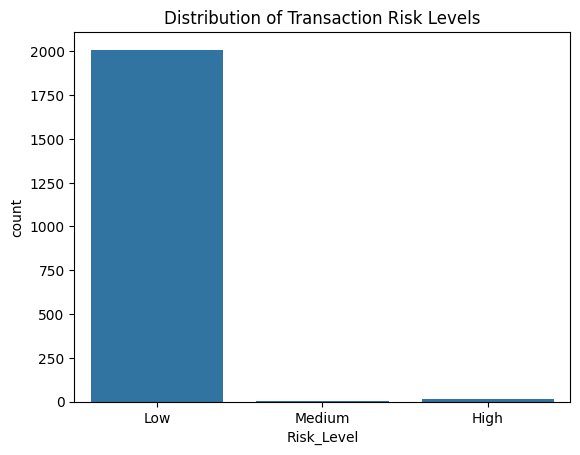

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x='Risk_Level', data=results, order=['Low','Medium','High'])
plt.title('Distribution of Transaction Risk Levels')
plt.show()

In [69]:
pipeline_xgb.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['tx_last_3' 'time_diff' 'std_amount_user']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [09:43:21] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['step', 'amount',
                                                   'oldbalanceOrg',
                                                   'newbalanceOrig',
                                                   'oldbalanceDest',
                                                   'newbalanceDest',
                                                   'unusuallogin',
                                                   'isFlaggedFraud',
                                                   'tx_count_user',
                                                   'tx_per_hour', 'tx_last_3',
                                                   'time_diff',
                                                   'avg_amount_user',
                                                   'a...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

Getting feature importance

In [70]:
# Suppose your pipeline is called 'pipeline_xgb'
model = pipeline_xgb.named_steps['model']  # 'model' is the name you gave in pipeline


In [71]:
# Transform the data
X_transformed = pipeline_xgb.named_steps['preprocess'].fit_transform(X_train)

# Get number of features after preprocessing
n_features = X_transformed.shape[1]

# For simplicity, create generic names if exact names unavailable
feature_names = [f'feature_{i}' for i in range(n_features)]


/usr/local/lib/python3.12/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['tx_last_3' 'time_diff' 'std_amount_user']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


In [72]:
import pandas as pd

importances = model.feature_importances_
feat_imp = pd.Series(importances, index=feature_names)
feat_imp = feat_imp.sort_values(ascending=False)


/tmp/ipython-input-1866586882.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_features.values, y=top_features.index, palette="viridis")


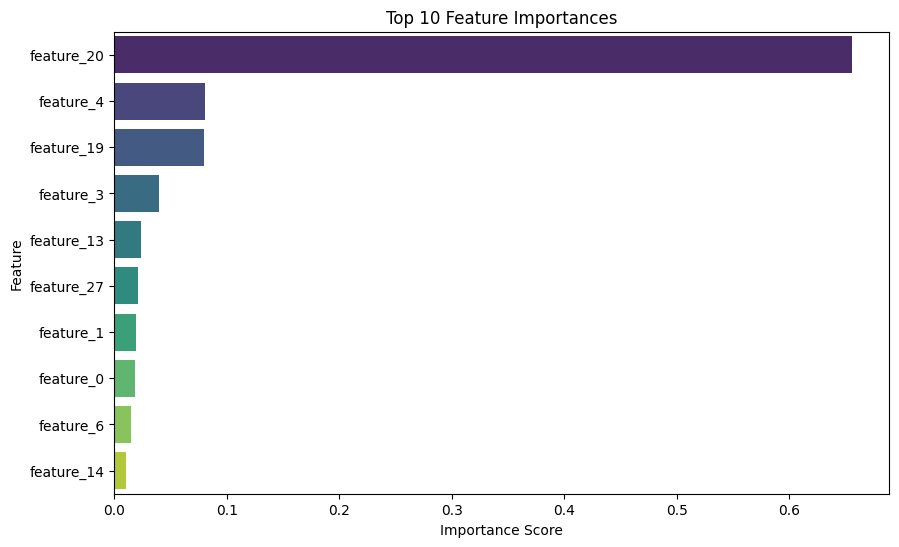

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns

top_features = feat_imp.head(10)
plt.figure(figsize=(10,6))
sns.barplot(x=top_features.values, y=top_features.index, palette="viridis")
plt.title("Top 10 Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.show()


Saving the model for **deployment**

In [74]:
import joblib
joblib.dump(best_model, "fraud_detection_model.pkl")


['fraud_detection_model.pkl']

In [75]:
from google.colab import files
files.download("fraud_detection_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>